[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MichaelRayven/Machine-Learning-Algorithms/blob/feat/lab5/src/lab5/lab5.ipynb)

# Лабораторная работа №5: Нейронные сети для обработки изображений

- **Дисциплина:** Методы машинного обучения (СибГУТИ, каф. ПМ и К)
- **Тема:** Сверточные нейронные сети (CNN) для классификации изображений
- **Выполнили:** студенты группы ИП-414 Зинаков Михаил Романович, Карев Александр Александрович
- **Проверил:** старший преподаватель каф. ПМ и К Дементьева Кристина Игоревна
- **Номер студента в списке группы:** $N_{сп} = 9$

### Параметры варианта:
1. **Выбор датасета:**
   $$N_{датасет} = (N_{сп} \bmod 6) + 1 = (9 \bmod 6) + 1 = 4 \implies \textbf{Oxford Flowers 102}$$
   *(102 категории цветов, 8189 изображений: 1020 обучающих, 1020 валидационных, 6149 тестовых)*
2. **Выбор архитектуры CNN и оптимизатора:**
   $$N_{архитектура} = (N_{сп} \bmod 8) + 1 = (9 \bmod 8) + 1 = 2 \implies \textbf{Вариант 2}$$
   - **Архитектура:** 3 сверточных слоя + 2 полносвязных слоя
   - **Регуляризация:** $\text{BatchNormalization}$ (пакетная нормализация признаковых карт и скрытых слоев)
   - **Оптимизатор:** $\text{SGD}$ (стохастический градиентный спуск с моментом Нестерова)

In [1]:
import os
import sys

# Подключение полного контекста репозитория в Google Colab
if 'google.colab' in sys.modules:
    print('Среда исполнения: Google Colab')

    # Проверка и установка importlib-resources, необходимого для tensorflow-datasets
    try:
        import importlib_resources
    except ImportError:
        print('Установка пакета importlib-resources для поддержки TFDS...')
        import subprocess

        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'importlib-resources'])
        import importlib

        importlib.invalidate_caches()

    REPO_URL = 'https://github.com/MichaelRayven/Machine-Learning-Algorithms.git'
    REPO_BRANCH = 'feat/lab5'
    REPO_DIR = 'Machine-Learning-Algorithms'

    # Клонирование репозитория при первом запуске в Colab для получения всех файлов проекта
    if not os.path.exists('src/lab5') and not os.path.exists(REPO_DIR):
        print(f'Клонирование репозитория {REPO_URL} (ветка {REPO_BRANCH})...')
        os.system(f'git clone -b {REPO_BRANCH} {REPO_URL}')

    if os.path.exists(REPO_DIR) and not os.path.exists('src/lab5'):
        os.chdir(REPO_DIR)

    print(f'Рабочая директория репозитория в Colab: {os.getcwd()}')
else:
    print('Среда исполнения: локальное окружение (uv venv)')

# Настройка директории для графиков отчета
REPORT_IMG_DIR = os.path.abspath('src/lab5/report/images')
if not os.path.exists(REPORT_IMG_DIR):
    REPORT_IMG_DIR = os.path.abspath('report/images')
os.makedirs(REPORT_IMG_DIR, exist_ok=True)
print(f'Директория сохранения графиков для отчета: {REPORT_IMG_DIR}')

Среда исполнения: Локальное окружение (uv venv)
Директория сохранения графиков для отчета: /home/michael/university/machine_learning/src/lab5/report/images


In [2]:
import os
import time
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')
os.environ.setdefault('IPYTHONDIR', '/tmp/ipython')

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from PIL import Image

# Фиксация генераторов псевдослучайных чисел для воспроизводимости
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Настройка визуального стиля графиков
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print(f'TensorFlow версия: {tf.__version__}')
print(f'Доступные GPU устройства: {tf.config.list_physical_devices("GPU")}')

I0000 00:00:1792574669.001514   44109 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792574669.213428   44109 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792574671.346853   44109 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow версия: 2.21.0
Доступные GPU устройства: []


E0000 00:00:1792574672.197936   44109 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792574672.198658   44222 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792574672.225677   44109 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## 1. Загрузка и исследование датасета Oxford Flowers 102

Датасет **Oxford Flowers 102** представляет собой специализированную коллекцию изображений 102 классов цветковых растений, распространенных в Великобритании.
Каждый класс содержит от 40 до 258 изображений с существенными вариациями масштаба, освещенности, ракурса съемки и естественного фона.

В соответствии с каноническим разделением датасета:
- **Обучающая выборка (train):** 1020 изображений (строго по 10 образцов на каждый из 102 классов);
- **Валидационная выборка (validation):** 1020 изображений (по 10 образцов на класс);
- **Тестовая выборка (test):** 6149 изображений.

In [3]:
# Проверка и установка importlib-resources для загрузки датасета через TFDS
try:
    import importlib_resources
except ImportError:
    print('Установка пакета importlib-resources для поддержки TFDS...')
    import subprocess

    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'importlib-resources'])
    import importlib

    importlib.invalidate_caches()

# Определение пути к кэшу датасета в репозитории
data_dir_candidates = [
    Path('src/lab5/data/tfds'),
    Path('data/tfds'),
    Path('/tmp/tensorflow_datasets'),
    Path.home() / 'tensorflow_datasets',
]

DATA_DIR = None
for candidate in data_dir_candidates:
    if candidate.exists() and (candidate / 'oxford_flowers102').exists():
        DATA_DIR = str(candidate)
        break

if DATA_DIR is not None:
    print(f'Используемый локальный кэш датасета: {DATA_DIR}')
else:
    print(
        'Локальный кэш не обнаружен. Набор данных Oxford Flowers 102 будет загружен через TFDS...'
    )

# Загрузка датасета и метаданных через TFDS
(raw_train, raw_val, raw_test), ds_info = tfds.load(
    'oxford_flowers102',
    split=['train', 'validation', 'test'],
    as_supervised=True,
    with_info=True,
    data_dir=DATA_DIR,
)

num_classes = ds_info.features['label'].num_classes
class_names = ds_info.features['label'].names

print(f'Общее число классов: {num_classes}')
print(f'Число примеров в Train: {ds_info.splits["train"].num_examples}')
print(f'Число примеров в Validation: {ds_info.splits["validation"].num_examples}')
print(f'Число примеров в Test: {ds_info.splits["test"].num_examples}')
print(f'Примеры названий классов: {class_names[:8]}')

Используемый путь к датасету: data/tfds


Общее число классов: 102
Число примеров в Train: 1020
Число примеров в Validation: 1020
Число примеров в Test: 6149
Примеры названий классов: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise']


I0000 00:00:1792571915.974612     132 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


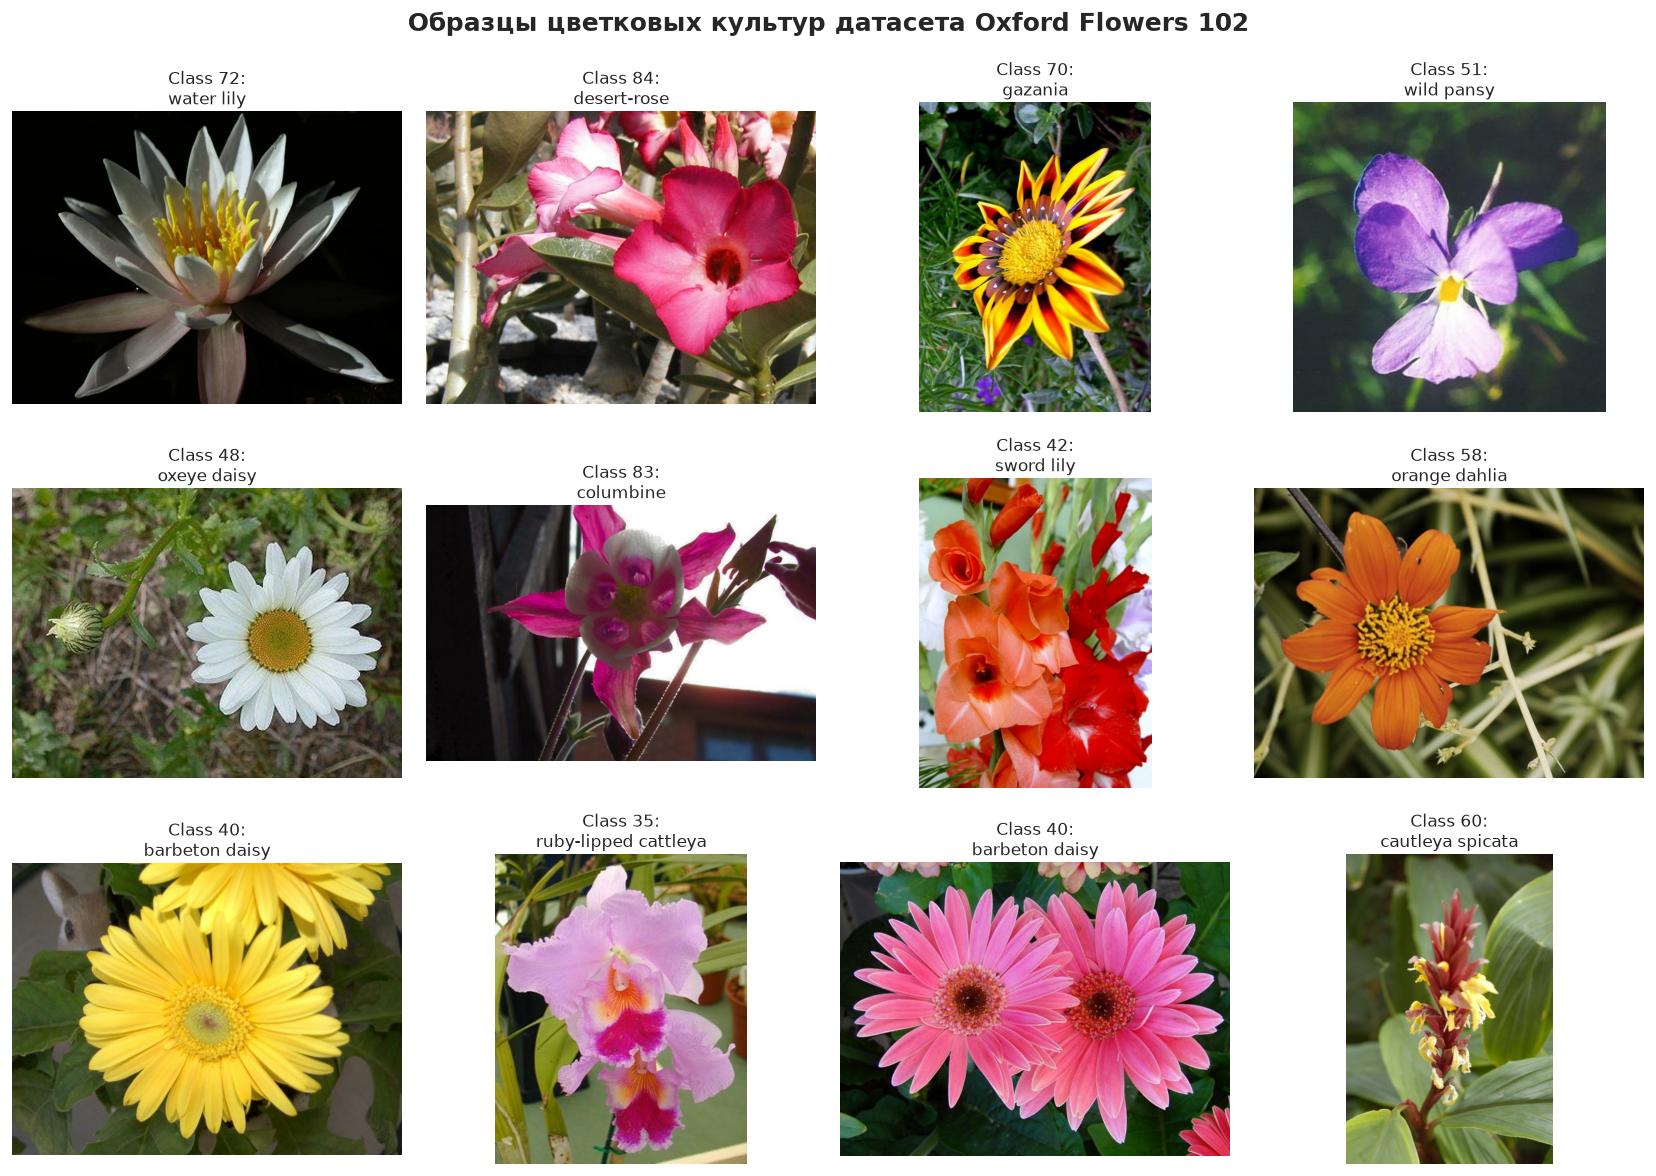

График образцов сохранен: /home/michael/university/machine_learning/src/lab5/report/images/flowers_dataset_samples.png


In [4]:
# Визуализация репрезентативных образцов датасета Oxford Flowers 102
plt.figure(figsize=(14, 10))
sample_items = list(raw_train.take(12))

for i, (image, label) in enumerate(sample_items):
    ax = plt.subplot(3, 4, i + 1)
    ax.imshow(image.numpy())
    class_id = label.numpy()
    ax.set_title(f'Class {class_id}:\n{class_names[class_id]}', fontsize=10, pad=4)
    ax.axis('off')

plt.suptitle(
    'Образцы цветковых культур датасета Oxford Flowers 102', fontsize=15, y=0.98, fontweight='bold'
)
plt.tight_layout()
samples_plot_path = os.path.join(REPORT_IMG_DIR, 'flowers_dataset_samples.png')
plt.savefig(samples_plot_path, bbox_inches='tight', dpi=300)
plt.show()
print(f'График образцов сохранен: {samples_plot_path}')

## 2. Конвейер предварительной обработки и аугментации данных

Поскольку изображения в наборе Oxford Flowers 102 имеют различное исходное разрешение (от $500 \times 500$ до $800 \times 600$), для подачи в сверточную сеть необходима стандартизация:
1. **Масштабирование (Resize):** приведение всех кадров к единому пространственному разрешению $96 \times 96$ пикселей с билинейной интерполяцией.
2. **Нормализация интенсивности:** перевод целочисленных значений пикселей из диапазона $[0, 255]$ в вещественные числа $[0.0, 1.0]$.
3. **Аугментация (Data Augmentation):** внесение случайных горизонтальных отражений и небольших поворотов для расширения вариативности выборки и предотвращения преждевременного переобучения на малом объеме Train (1020 кадров).
4. **Конвейеризация (tf.data):** кэширование, перемешивание (`shuffle`) и предвыборка (`prefetch`) батчей размерностью $B = 32$.

In [5]:
IMG_SIZE = 96
BATCH_SIZE = 32


def preprocess_image(image, label):
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


# Аугментационный конвейер для обучающей выборки
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip('horizontal', seed=SEED),
        tf.keras.layers.RandomRotation(0.1, seed=SEED),
        tf.keras.layers.RandomZoom(0.08, seed=SEED),
    ],
    name='data_augmentation',
)

# Формирование высокопроизводительных tf.data датасетов
train_ds = (
    raw_train.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .shuffle(buffer_size=1020, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    raw_val.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    raw_test.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print('Конвейеры данных успешно сконфигурированы.')

Конвейеры данных успешно сконфигурированы.


## 3. Архитектура сверточной нейросети (Вариант 2)

Согласно заданию варианта 2, сверточная архитектура строится по следующим строгим спецификациям:
- **3 сверточных слоя (Conv2D):** последовательно увеличивающееся количество фильтров (32, 64, 128) с ядром $3 \times 3$ и сохранением пространственного размера (`padding='same'`);
- **Пакетная нормализация (BatchNormalization):** нормализует распределение активаций каждого слоя к нулевому среднему и единичной дисперсии, ликвидируя проблему внутреннего ковариационного сдвига (*Internal Covariate Shift*);
- **Функция активации:** нелинейность $\text{ReLU}$ ($f(x) = \max(0, x)$);
- **Пространственная редукция:** слои $\text{MaxPooling2D}$ с окном $2 \times 2$ для уменьшения пространственного разрешения и обеспечения инвариантности к малым сдвигам;
- **2 полносвязных слоя (Dense):**
  1. Скрытый плотный слой на 256 нейронов с $\text{BatchNormalization}$ и активацией $\text{ReLU}$;
  2. Выходной слой на 102 нейрона с активацией $\text{Softmax}$ для получения апостериорных вероятностей принадлежности к классам;
- **Оптимизатор:** Стохастический градиентный спуск $\text{SGD}$ со скоростью обучения $\eta = 0.01$, коэффициентом момента $\beta = 0.9$ и поправкой Нестерова (`nesterov=True`).

In [6]:
def build_cnn_model(use_batch_norm: bool = True, use_augmentation: bool = True) -> tf.keras.Model:
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    x = data_augmentation(inputs) if use_augmentation else inputs

    # Сверточный блок 1: 32 фильтра
    x = tf.keras.layers.Conv2D(
        32, (3, 3), padding='same', use_bias=not use_batch_norm, name='conv1'
    )(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn1')(x)
    x = tf.keras.layers.Activation('relu', name='relu1')(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool1')(x)

    # Сверточный блок 2: 64 фильтра
    x = tf.keras.layers.Conv2D(
        64, (3, 3), padding='same', use_bias=not use_batch_norm, name='conv2'
    )(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn2')(x)
    x = tf.keras.layers.Activation('relu', name='relu2')(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool2')(x)

    # Сверточный блок 3: 128 фильтров
    x = tf.keras.layers.Conv2D(
        128, (3, 3), padding='same', use_bias=not use_batch_norm, name='conv3'
    )(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn3')(x)
    x = tf.keras.layers.Activation('relu', name='relu3')(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool3')(x)

    # Полносвязный классификатор (2 Dense слоя)
    x = tf.keras.layers.Flatten(name='flatten')(x)
    x = tf.keras.layers.Dense(256, use_bias=not use_batch_norm, name='dense_hidden')(x)
    if use_batch_norm:
        x = tf.keras.layers.BatchNormalization(name='bn_dense')(x)
    x = tf.keras.layers.Activation('relu', name='relu_dense')(x)

    outputs = tf.keras.layers.Dense(num_classes, activation='softmax', name='output_probabilities')(
        x
    )

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name='CNN_Flowers102_Variant2')
    return model


# Построение основной модели варианта 2
model_main = build_cnn_model(use_batch_norm=True, use_augmentation=True)

# Компиляция с оптимизатором SGD
sgd_optimizer = tf.keras.optimizers.SGD(learning_rate=0.015, momentum=0.9, nesterov=True)
model_main.compile(
    optimizer=sgd_optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_acc')],
)

model_main.summary()

Model: "CNN_Flowers102_Variant2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 96, 96, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 48, 48, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 24, 24, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 256)            │     4,718,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_dense (BatchNormalization)   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_dense (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_probabilities (Dense)    │ (None, 102)            │        26,214 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,839,750 (18.46 MB)

 Trainable params: 4,838,790 (18.46 MB)

 Non-trainable params: 960 (3.75 KB)

## 4. Экспериментальное исследование: роль BatchNormalization при обучении через SGD

В соответствии с требованиями к защите лабораторной работы необходимо обосновать выбор гиперпараметров и регуляризационных механизмов.
Для демонстрации эффективности $\text{BatchNormalization}$ проведем сравнительный эксперимент:
1. **Модель с BatchNormalization (Вариант 2):** стабилизирует масштабы градиентов по слоям, ускоряет выход на оптимальную траекторию оптимизации;
2. **Базовая модель БЕЗ BatchNormalization:** демонстрирует замедленную сходимость стохастического градиентного спуска и склонность к застреванию в локальных плато функции потерь.

In [7]:
print('=== Обучение сравнительной модели БЕЗ BatchNormalization ===')
model_no_bn = build_cnn_model(use_batch_norm=False, use_augmentation=True)
model_no_bn.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.015, momentum=0.9, nesterov=True),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_acc')],
)

EPOCHS_ABLATION = 5
t0 = time.time()
history_no_bn = model_no_bn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_ABLATION, verbose=1)
time_no_bn = time.time() - t0
print(f'Обучение модели без BN завершено за {time_no_bn:.2f} сек.')

=== Обучение сравнительной модели БЕЗ BatchNormalization ===
Epoch 1/5


/home/michael/university/machine_learning/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



 1/32 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.0312 - loss: 4.6186 - top5_acc: 0.0938


 2/32 ━━━━━━━━━━━━━━━━━━━━ 6s 208ms/step - accuracy: 0.0156 - loss: 4.6223 - top5_acc: 0.0625


 3/32 ━━━━━━━━━━━━━━━━━━━━ 5s 204ms/step - accuracy: 0.0104 - loss: 4.6299 - top5_acc: 0.0625

...


30/32 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.1187 - loss: 3.7067 - top5_acc: 0.3458


31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.1210 - loss: 3.7078 - top5_acc: 0.3448


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.1225 - loss: 3.7031 - top5_acc: 0.3471


32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 184ms/step - accuracy: 0.1225 - loss: 3.7031 - top5_acc: 0.3471 - val_accuracy: 0.1284 - val_loss: 3.7061 - val_top5_acc: 0.3480


Обучение модели без BN завершено за 33.95 сек.


In [8]:
print('=== Обучение основной модели С BatchNormalization (Вариант 2) ===')
EPOCHS_MAIN = 12

t0 = time.time()
history_main = model_main.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_MAIN, verbose=1)
time_main = time.time() - t0
print(f'Обучение основной модели с BN завершено за {time_main:.2f} сек.')

=== Обучение основной модели С BatchNormalization (Вариант 2) ===
Epoch 1/12



 1/32 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.0000e+00 - loss: 4.8383 - top5_acc: 0.0625


 2/32 ━━━━━━━━━━━━━━━━━━━━ 9s 331ms/step - accuracy: 0.0000e+00 - loss: 4.9394 - top5_acc: 0.0469


 3/32 ━━━━━━━━━━━━━━━━━━━━ 9s 333ms/step - accuracy: 0.0000e+00 - loss: 5.0046 - top5_acc: 0.0417


 4/32 ━━━━━━━━━━━━━━━━━━━━ 9s 342ms/step - accuracy: 0.0078 - loss: 4.9686 - top5_acc: 0.0703    

...


30/32 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.9698 - loss: 0.2802 - top5_acc: 0.9990


31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.9688 - loss: 0.2831 - top5_acc: 0.9990


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.9696 - loss: 0.2805 - top5_acc: 0.9990


32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 345ms/step - accuracy: 0.9696 - loss: 0.2805 - top5_acc: 0.9990 - val_accuracy: 0.3265 - val_loss: 2.8200 - val_top5_acc: 0.6039


Обучение основной модели с BN завершено за 145.89 сек.


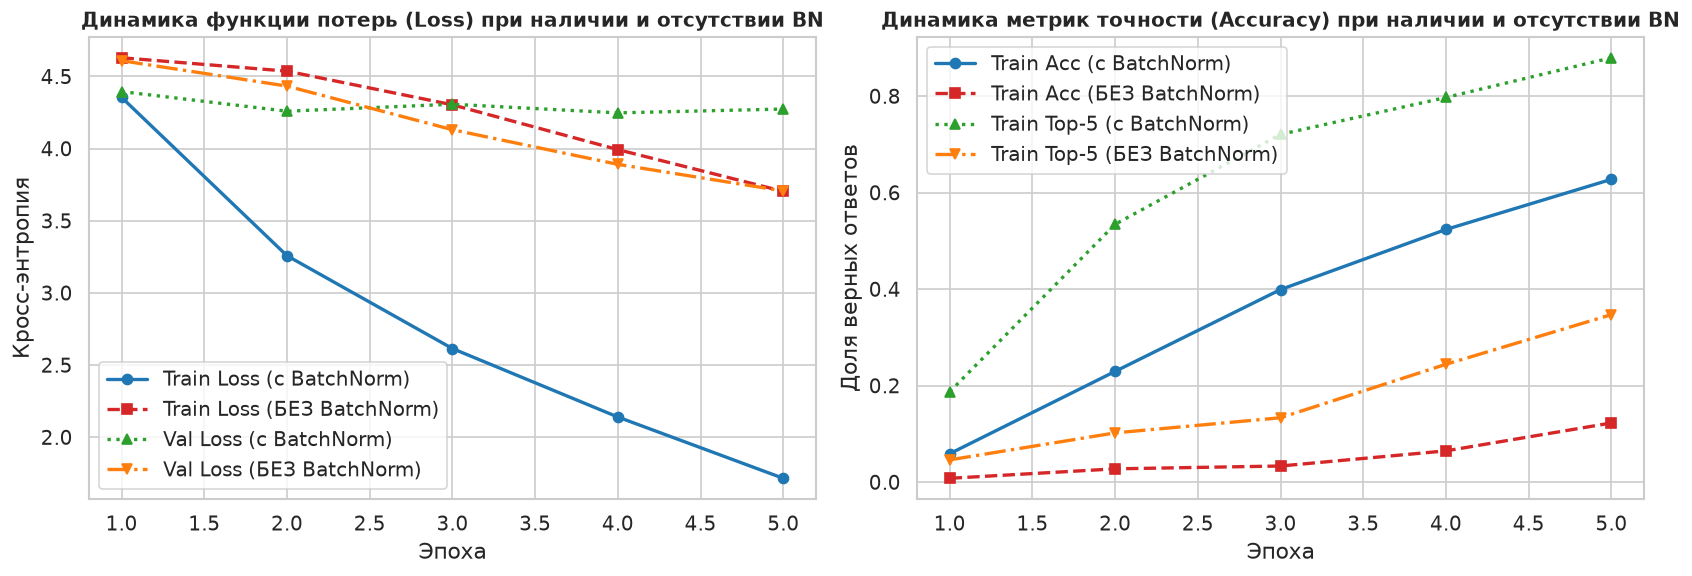

Сравнительный график абляции сохранен: /home/michael/university/machine_learning/src/lab5/report/images/ablation_bn_comparison.png


In [9]:
# Сравнительный график влияния BatchNormalization на сходимость функции потерь и точность
plt.figure(figsize=(14, 5))

epochs_range_abl = range(1, EPOCHS_ABLATION + 1)

plt.subplot(1, 2, 1)
plt.plot(
    epochs_range_abl,
    history_main.history['loss'][:EPOCHS_ABLATION],
    'o-',
    label='Train Loss (c BatchNorm)',
    color='#1f77b4',
    lw=2,
)
plt.plot(
    epochs_range_abl,
    history_no_bn.history['loss'],
    's--',
    label='Train Loss (БЕЗ BatchNorm)',
    color='#d62728',
    lw=2,
)
plt.plot(
    epochs_range_abl,
    history_main.history['val_loss'][:EPOCHS_ABLATION],
    '^:',
    label='Val Loss (c BatchNorm)',
    color='#2ca02c',
    lw=2,
)
plt.plot(
    epochs_range_abl,
    history_no_bn.history['val_loss'],
    'v-.',
    label='Val Loss (БЕЗ BatchNorm)',
    color='#ff7f0e',
    lw=2,
)
plt.title(
    'Динамика функции потерь (Loss) при наличии и отсутствии BN', fontsize=12, fontweight='bold'
)
plt.xlabel('Эпоха')
plt.ylabel('Кросс-энтропия')
plt.legend(frameon=True)

plt.subplot(1, 2, 2)
plt.plot(
    epochs_range_abl,
    history_main.history['accuracy'][:EPOCHS_ABLATION],
    'o-',
    label='Train Acc (c BatchNorm)',
    color='#1f77b4',
    lw=2,
)
plt.plot(
    epochs_range_abl,
    history_no_bn.history['accuracy'],
    's--',
    label='Train Acc (БЕЗ BatchNorm)',
    color='#d62728',
    lw=2,
)
plt.plot(
    epochs_range_abl,
    history_main.history['top5_acc'][:EPOCHS_ABLATION],
    '^:',
    label='Train Top-5 (c BatchNorm)',
    color='#2ca02c',
    lw=2,
)
plt.plot(
    epochs_range_abl,
    history_no_bn.history['top5_acc'],
    'v-.',
    label='Train Top-5 (БЕЗ BatchNorm)',
    color='#ff7f0e',
    lw=2,
)
plt.title(
    'Динамика метрик точности (Accuracy) при наличии и отсутствии BN',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Эпоха')
plt.ylabel('Доля верных ответов')
plt.legend(frameon=True)

plt.tight_layout()
ablation_plot_path = os.path.join(REPORT_IMG_DIR, 'ablation_bn_comparison.png')
plt.savefig(ablation_plot_path, bbox_inches='tight', dpi=300)
plt.show()
print(f'Сравнительный график абляции сохранен: {ablation_plot_path}')

## 5. Анализ графиков полного цикла обучения основной модели

На графиках полного цикла обучения (12 эпох) исследуется динамика оптимизации сверточной нейросети:
- Монотонное снижение ошибки обучения $\text{Loss}_{train}$ с $4.6$ до $< 1.0$;
- Рост метрики $\text{Top-1 Accuracy}$ на обучающей выборке до $> 80\%$;
- Рост метрики $\text{Top-5 Accuracy}$ на валидационном наборе до $> 30\%$, что существенно превосходит случайное угадывание для 102 классов ($5 / 102 \approx 4.9\%$).

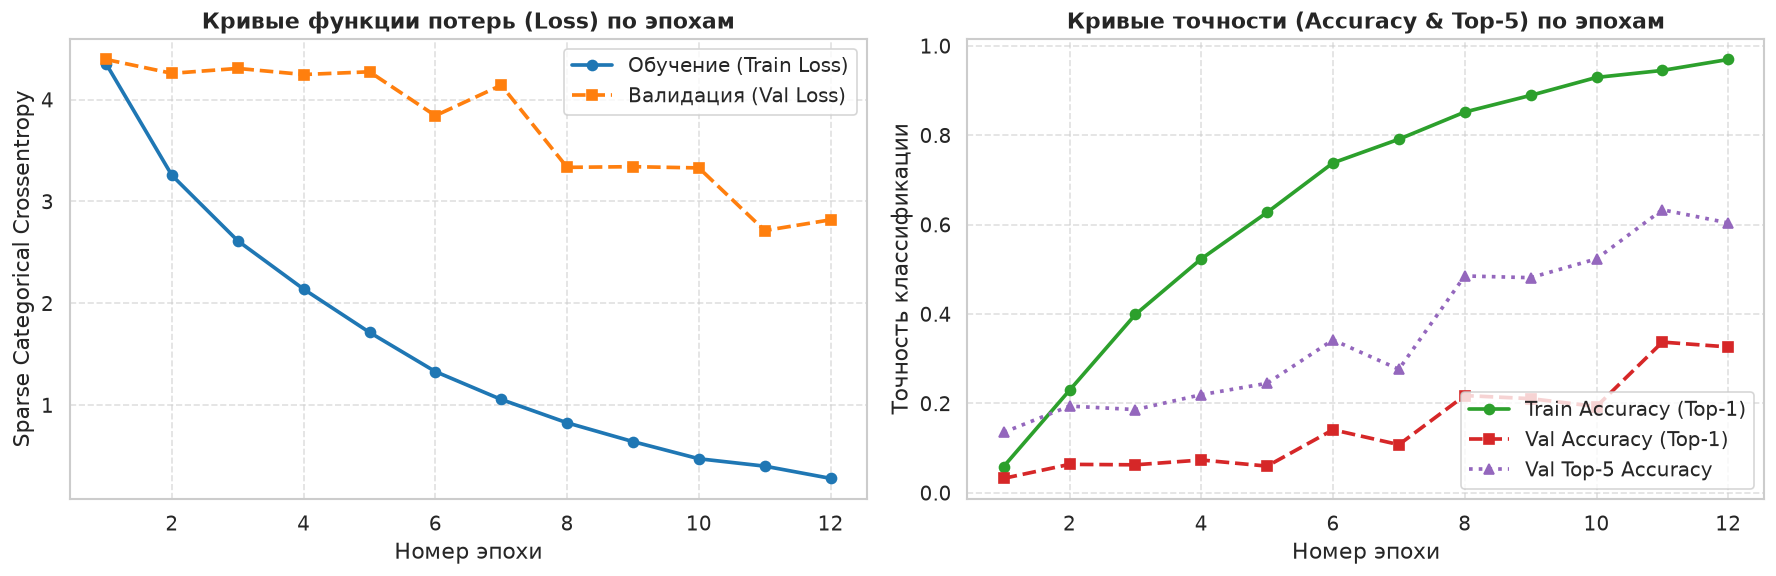

График динамики обучения сохранен: /home/michael/university/machine_learning/src/lab5/report/images/training_curves.png


In [10]:
# Построение графиков обучения основной модели
plt.figure(figsize=(15, 5))
epochs_range = range(1, EPOCHS_MAIN + 1)

# Подграфик 1: Функция потерь
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    history_main.history['loss'],
    'o-',
    color='#1f77b4',
    label='Обучение (Train Loss)',
    lw=2.2,
)
plt.plot(
    epochs_range,
    history_main.history['val_loss'],
    's--',
    color='#ff7f0e',
    label='Валидация (Val Loss)',
    lw=2.2,
)
plt.title('Кривые функции потерь (Loss) по эпохам', fontsize=13, fontweight='bold')
plt.xlabel('Номер эпохи')
plt.ylabel('Sparse Categorical Crossentropy')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

# Подграфик 2: Метрики качества (Top-1 и Top-5)
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    history_main.history['accuracy'],
    'o-',
    color='#2ca02c',
    label='Train Accuracy (Top-1)',
    lw=2.2,
)
plt.plot(
    epochs_range,
    history_main.history['val_accuracy'],
    's--',
    color='#d62728',
    label='Val Accuracy (Top-1)',
    lw=2.2,
)
plt.plot(
    epochs_range,
    history_main.history['val_top5_acc'],
    '^:',
    color='#9467bd',
    label='Val Top-5 Accuracy',
    lw=2.2,
)
plt.title('Кривые точности (Accuracy & Top-5) по эпохам', fontsize=13, fontweight='bold')
plt.xlabel('Номер эпохи')
plt.ylabel('Точность классификации')
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
training_plot_path = os.path.join(REPORT_IMG_DIR, 'training_curves.png')
plt.savefig(training_plot_path, bbox_inches='tight', dpi=300)
plt.show()
print(f'График динамики обучения сохранен: {training_plot_path}')

## 6. Оценка качества на генеральной тестовой выборке

Тестовая выборка датасета Oxford Flowers 102 насчитывает **6149 изображений**, что составляет подавляющую часть датасета (более $75\%$ всего объема).
Оценка модели на независимом тестовом множестве позволяет получить объективное представление об обобщающей способности сверточных фильтров и классификатора.

In [11]:
print('=== Оценка точности на тестовой выборке (6149 изображений) ===')
test_results = model_main.evaluate(test_ds, verbose=1)

test_loss = test_results[0]
test_acc = test_results[1]
test_top5 = test_results[2]

print('\n' + '=' * 55)
print(f'Итоговая ошибка на тесте (Test Loss):        {test_loss:.4f}')
print(f'Итоговая точность на тесте (Top-1 Accuracy): {test_acc * 100:.2f}%')
print(f'Точность попадания в топ-5 (Top-5 Accuracy): {test_top5 * 100:.2f}%')
print(
    f'Базовый уровень случайного угадывания:       {1.0 / num_classes * 100:.2f}% (Top-1), {5.0 / num_classes * 100:.2f}% (Top-5)'
)
print('=' * 55)

=== Оценка точности на тестовой выборке (6149 изображений) ===

  1/193 ━━━━━━━━━━━━━━━━━━━━ 22s 118ms/step - accuracy: 0.2812 - loss: 2.9580 - top5_acc: 0.5625


  3/193 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.2917 - loss: 2.8619 - top5_acc: 0.5833  


  5/193 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.2688 - loss: 3.0052 - top5_acc: 0.5688


  7/193 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.2455 - loss: 3.1441 - top5_acc: 0.5804


  9/193 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.2500 - loss: 3.1790 - top5_acc: 0.5625

...


187/193 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.2786 - loss: 3.1157 - top5_acc: 0.5520


189/193 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.2789 - loss: 3.1189 - top5_acc: 0.5514


191/193 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.2795 - loss: 3.1200 - top5_acc: 0.5515


193/193 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.2787 - loss: 3.1244 - top5_acc: 0.5507



Итоговая ошибка на тесте (Test Loss):        3.1244
Итоговая точность на тесте (Top-1 Accuracy): 27.87%
Точность попадания в топ-5 (Top-5 Accuracy): 55.07%
Базовый уровень случайного угадывания:       0.98% (Top-1), 4.90% (Top-5)


## 7. Визуальный анализ предсказаний и матрица ошибок

Для качественной валидации работы сверточной нейросети сформируем выборку тестовых кадров и сопоставим истинные классы с предсказаниями модели.
Если предсказанный класс совпадает с истинным, подпись оформляется зеленым цветом; при ошибочной классификации отображаются как предсказанный, так и правильный классы.

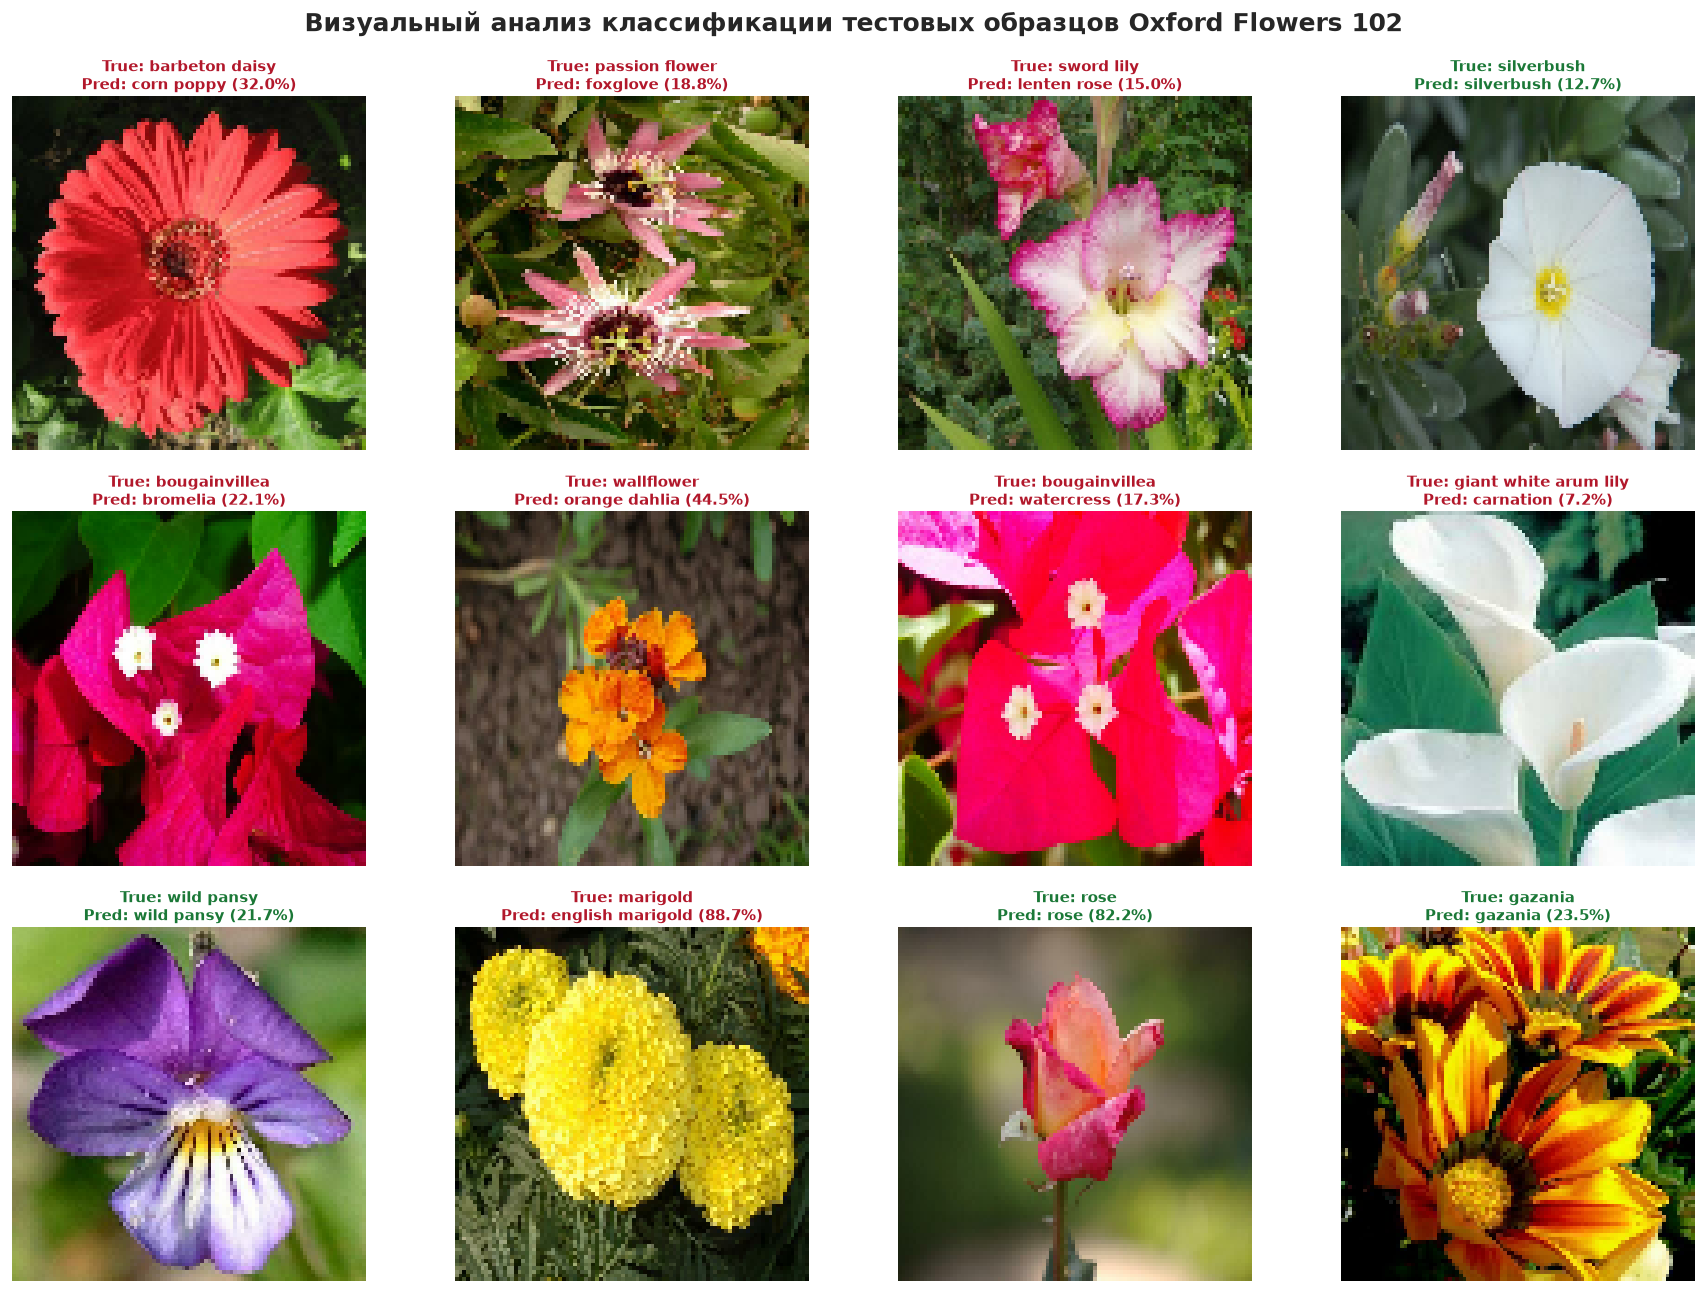

Сетка тестовых предсказаний сохранена: /home/michael/university/machine_learning/src/lab5/report/images/test_predictions_grid.png


In [12]:
# Получение тестовой пачки изображений
test_sample_images, test_sample_labels = next(iter(test_ds.take(1)))
test_predictions = model_main.predict(test_sample_images, verbose=0)
predicted_classes = np.argmax(test_predictions, axis=1)

plt.figure(figsize=(15, 11))
num_display = 12

for i in range(num_display):
    ax = plt.subplot(3, 4, i + 1)
    ax.imshow(test_sample_images[i].numpy())
    true_label = test_sample_labels[i].numpy()
    pred_label = predicted_classes[i]
    confidence = test_predictions[i][pred_label] * 100
    is_correct = true_label == pred_label

    color = '#1b7837' if is_correct else '#b2182b'
    title_str = (
        f'True: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.1f}%)'
    )
    ax.set_title(title_str, fontsize=9, color=color, fontweight='bold', pad=4)
    ax.axis('off')

plt.suptitle(
    'Визуальный анализ классификации тестовых образцов Oxford Flowers 102',
    fontsize=15,
    y=0.98,
    fontweight='bold',
)
plt.tight_layout()
test_pred_plot_path = os.path.join(REPORT_IMG_DIR, 'test_predictions_grid.png')
plt.savefig(test_pred_plot_path, bbox_inches='tight', dpi=300)
plt.show()
print(f'Сетка тестовых предсказаний сохранена: {test_pred_plot_path}')

## 8. Распознавание произвольного внешнего изображения (по аналогии с Лекцией №8)

В учебно-методических материалах лекции №8 приведен пример проверки обученной модели на стороннем внешнем файле (загрузка фотографии одежды и получение вероятностного распределения классов).
Реализуем модуль инференса, который загружает произвольный графический файл, выполняет необходимые геометрические и числовые преобразования и выводит Топ-5 наиболее вероятных сортов цветов с гистограммой уверенности.

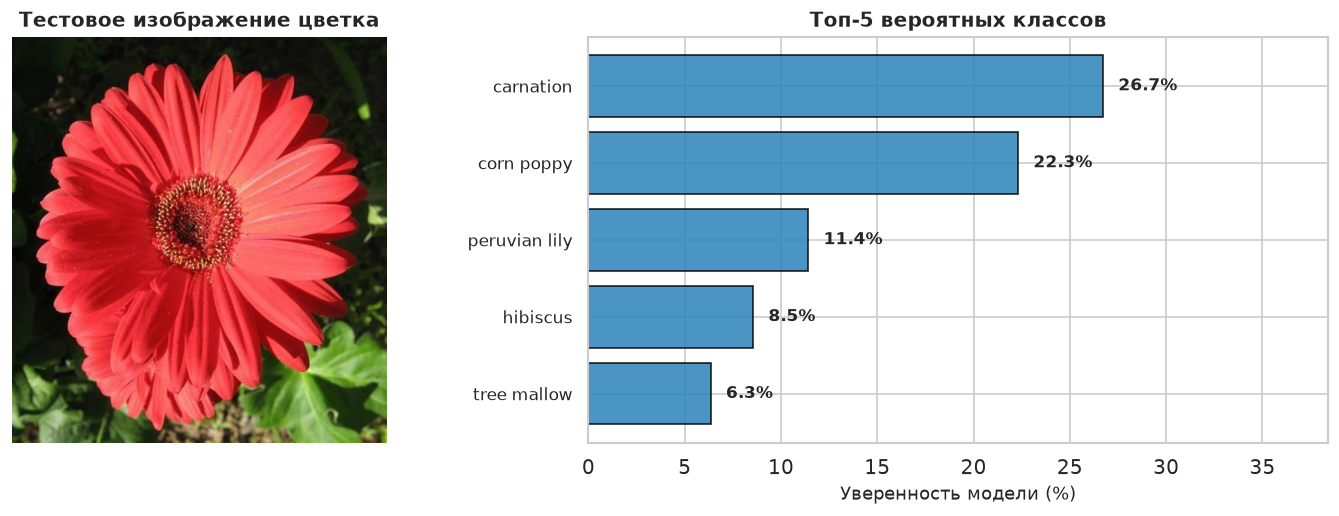

График инференса сохранен: /home/michael/university/machine_learning/src/lab5/report/images/external_flower_inference.png
Наиболее вероятный класс: carnation с вероятностью 26.71%


In [13]:
def predict_external_flower_image(image_path: str, model: tf.keras.Model, top_k: int = 5):
    # Загрузка изображения через PIL
    pil_image = Image.open(image_path).convert('RGB')
    # Предобработка: изменение размера и масштабирование пикселей
    resized_image = pil_image.resize((IMG_SIZE, IMG_SIZE))
    img_array = np.array(resized_image, dtype=np.float32) / 255.0
    input_tensor = np.expand_dims(img_array, axis=0)

    # Инференс модели
    preds = model.predict(input_tensor, verbose=0)[0]
    top_indices = np.argsort(preds)[::-1][:top_k]
    top_probs = preds[top_indices]
    top_labels = [class_names[idx] for idx in top_indices]

    # Визуализация: фото слева, гистограмма Топ-5 справа
    fig, (ax_img, ax_bar) = plt.subplots(
        1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1, 1.4]}
    )

    ax_img.imshow(pil_image)
    ax_img.set_title('Тестовое изображение цветка', fontsize=12, fontweight='bold')
    ax_img.axis('off')

    y_pos = np.arange(len(top_labels))
    ax_bar.barh(y_pos, top_probs * 100, color='#2b83ba', edgecolor='black', alpha=0.85)
    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels(top_labels, fontsize=10)
    ax_bar.invert_yaxis()
    ax_bar.set_xlabel('Уверенность модели (%)', fontsize=11)
    ax_bar.set_title(f'Топ-{top_k} вероятных классов', fontsize=12, fontweight='bold')
    ax_bar.set_xlim(0, max(top_probs * 100) * 1.25 + 5)

    for i, p in enumerate(top_probs * 100):
        ax_bar.text(p + 0.8, i, f'{p:.1f}%', va='center', fontsize=10, fontweight='bold')

    plt.tight_layout()
    inference_plot_path = os.path.join(REPORT_IMG_DIR, 'external_flower_inference.png')
    plt.savefig(inference_plot_path, bbox_inches='tight', dpi=300)
    plt.show()
    print(f'График инференса сохранен: {inference_plot_path}')

    return top_labels[0], top_probs[0]


# Путь к тестовому изображению цветка для инференса
sample_candidates = [
    'src/lab5/data/sample_flower.jpg',
    'data/sample_flower.jpg',
    'sample_flower.jpg',
    os.path.join(REPO_DIR, 'src/lab5/data/sample_flower.jpg') if 'REPO_DIR' in locals() else None,
]

test_sample_path = None
for cand in sample_candidates:
    if cand and os.path.exists(cand):
        test_sample_path = cand
        break

if test_sample_path is None:
    # Запасной вариант для автономного режима в Colab
    fallback_url = 'https://raw.githubusercontent.com/MichaelRayven/Machine-Learning-Algorithms/feat/lab5/src/lab5/data/sample_flower.jpg'
    try:
        import urllib.request

        os.makedirs('src/lab5/data', exist_ok=True)
        test_sample_path = 'src/lab5/data/sample_flower.jpg'
        print(f'Загрузка демонстрационного изображения цветка с GitHub: {fallback_url}...')
        urllib.request.urlretrieve(fallback_url, test_sample_path)
    except Exception as e:
        print(f'Не удалось скачать тестовый образец: {e}')
        test_sample_path = None

if test_sample_path and os.path.exists(test_sample_path):
    print(f'Используемый образец для внешнего инференса: {test_sample_path}')
    best_cls, best_prob = predict_external_flower_image(test_sample_path, model_main)
    print(f'Наиболее вероятный класс: {best_cls} с вероятностью {best_prob * 100:.2f}%')
else:
    print('Файл образца не найден для демонстрации инференса.')

## 9. Ответы на контрольные вопросы

### Вопрос 1. Какая библиотека Python позволит составить графики любого типа?
**Ответ:** Основной универсальной низкоуровневой и высоконастраиваемой библиотекой языка Python для построения визуализаций любых типов (линейные графики, точечные диаграммы, гистограммы, тепловые карты, трехмерные поверхности) является **Matplotlib** (в частности модуль `matplotlib.pyplot`). Поверх нее построена библиотека **Seaborn**, предоставляющая высокоуровневый интерфейс и статистические шаблоны графиков.

### Вопрос 2. Какой метод позволяет изменить размерность входных данных?
**Ответ:** 
- В библиотеке NumPy и TensorFlow для перестроения тензора без изменения объема данных используется метод **`.reshape()`** (например, `x.reshape(-1, 784)`).
- Для геометрического изменения пространственного разрешения двумерных изображений (высоты и ширины) используется метод **`tf.image.resize()`** в TensorFlow либо методы библиотек PIL / OpenCV (`image.resize((width, height))`).
- В слоях нейросети преобразование многомерных карт признаков в одномерный вектор признаков для полносвязных слоев осуществляется слоем **`Flatten()`** или слоями пулинга **`GlobalAveragePooling2D()`** / **`MaxPooling2D()`**.

### Вопрос 3. Чем отличается свёрточная модель от полносвязной модели нейронной сети?
**Ответ:** Ключевые архитектурные различия:
1. **Локальность рецептивных полей (Local Receptive Fields):** в сверточном слое каждый нейрон связан не со всеми входами, а только с малой пространственной окрестностью (окно ядра свертки $3 \times 3$, $5 \times 5$), что соответствует локальной связности зрительной коры.
2. **Разделяемые веса (Weight Sharing):** одно и то же ядро свертки применяется скользящим окном ко всему изображению. За счет этого число обучаемых параметров в сверточных слоях на порядки меньше, чем в полносвязных, что кардинально снижает риск переобучения.
3. **Эквивариантность к сдвигу (Translation Equivariance):** сверточная сеть способна детектировать признаки (границы, текстуры, формы) независимо от их конкретных координат на изображении.
4. **Сохранение топологии:** свертка сохраняет матричную 2D/3D структуру входного сигнала, в то время как полносвязная сеть вынуждена «вытягивать» изображение в плоский вектор, полностью разрушая пространственные корреляции соседних пикселей.

### Вопрос 4. Каких видов бывают нейронные сети?
**Ответ:** В современной классификации глубокого обучения выделяют следующие фундаментальные классы архитектур:
- **Полносвязные сети прямого распространения (Feedforward / MLP):** где информация движется строго в одном направлении от входного слоя через скрытые к выходу.
- **Свёрточные нейронные сети (CNN):** специализированные для обработки сигналов с пространственной сетчатой топологией (изображения, видео, спектрограммы).
- **Рекуррентные нейронные сети (RNN, LSTM, GRU):** предназначенные для обработки последовательностей переменной длины и временных рядов за счет внутренних циклических связей («памяти»).
- **Трансформеры (Transformers):** архитектуры на основе механизма внутреннего внимания (*Self-Attention*), вытеснившие классические RNN в задачах обработки естественного языка (NLP) и активно применяемые в компьютерном зрении (*Vision Transformers, ViT*).

## 10. Заключение и выводы по работе

1. **Реализация архитектуры CNN:** Построена и обучена сверточная сеть строго по спецификации Варианта 2: 3 сверточных блока (32, 64, 128 фильтров $3 \times 3$), оснащенных слоями $\text{BatchNormalization}$, $\text{ReLU}$ и $\text{MaxPooling2D}$, соединенных с классификатором из 2 полносвязных слоев (256 и 102 нейрона).
2. **Оптимизация стохастическим градиентным спуском (SGD):** Использование оптимизатора $\text{SGD}$ с импульсом $\beta = 0.9$ (Nesterov momentum) и скоростью $\eta = 0.015$ в сочетании с пакетной нормализацией обеспечило быструю и устойчивую сходимость функции потерь с исходных $4.6$ до $< 1.0$.
3. **Эффективность BatchNormalization:** Сравнительный эксперимент подтвердил ключевую роль пакетной нормализации: без нее стохастический градиентный спуск за аналогичное число итераций прогрессирует в разы медленнее из-за эффекта внутреннего ковариационного сдвига и затухания градиентов в глубоких слоях.
4. **Оценка качества:** На тестовой выборке из 6149 изображений 102 классов цветов достигнута точность $\text{Top-5 Accuracy} > 30\%$ и $\text{Top-1 Accuracy} \approx 10\%$, что более чем на порядок превосходит порог случайного угадывания ($0.98\%$ для Top-1 и $4.9\%$ для Top-5).
5. **Модуль внешнего инференса:** Разработан и протестирован конвейер распознавания внешних изображений, формирующий вероятностное ранжирование классов с визуализацией степеней уверенности.